<a href="https://colab.research.google.com/github/harshitasdev8/SuSiE-Testing/blob/data_testing/SuSiE_Comparative_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [28]:
%%R
if (!requireNamespace("susieR", quietly = TRUE)) {
  install.packages("susieR", repos = "https://cloud.r-project.org")
}
library(susieR)
cat("susieR loaded\n")

susieR loaded


In [29]:
import os

!apt-get install -y bcftools tabix > /dev/null 2>&1

# list of European samples
!wget -q -O panel.txt https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/integrated_call_samples_v3.20130502.ALL.panel
!awk '$3=="EUR"{print $1}' panel.txt > eur.txt
!wc -l eur.txt

# one 500 kb window on chromosome 22 (change REGION to try others)
URL = "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz"
REGION = "22:30000000-30500000"

!bcftools view -r {REGION} -S eur.txt -m2 -M2 -v snps {URL} | bcftools query -f '%POS[\t%GT]\n' > geno.txt
!wc -l geno.txt

503 eur.txt
13118 geno.txt


In [30]:
F = "ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz"
REGION = "22:30000000-30500000"
!bcftools view -r {REGION} -S eur.txt -m2 -M2 -v snps {F} | bcftools query -f '%POS[\t%GT]\n' > geno.txt
!wc -l geno.txt
!head -c 200 geno.txt

[E::hts_open_format] Failed to open file "ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz" : No such file or directory
Failed to read from ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz: No such file or directory
Failed to read from standard input: unknown file type
0 geno.txt


In [31]:
import numpy as np

rows, pos = [], []
for line in open("geno.txt"):
    f = line.rstrip("\n").split("\t")
    pos.append(int(f[0]))
    # count copies of the variant allele: 0|0 -> 0, 0|1 or 1|0 -> 1, 1|1 -> 2
    rows.append([sum(int(a) for a in g.split("|")) for g in f[1:]])

X = np.array(rows).T                      # people x SNPs
pos = np.array(pos)

maf = X.mean(0) / 2
keep = np.minimum(maf, 1 - maf) >= 0.01   # drop very rare SNPs
X, pos = X[:, keep], pos[keep]

print("people x SNPs:", X.shape)
np.savetxt("X.csv", X, fmt="%d", delimiter=",")
np.savetxt("pos.csv", pos, fmt="%d")

people x SNPs: (0, 0)


/tmp/ipykernel_3256/2712778873.py:13: RuntimeWarning: Mean of empty slice.
  maf = X.mean(0) / 2
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [32]:
import subprocess, numpy as np, urllib.request

# 1) European sample list (done in Python to avoid shell quirks)
urllib.request.urlretrieve(
    "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/integrated_call_samples_v3.20130502.ALL.panel",
    "panel.txt")
eur = [l.split()[0] for l in open("panel.txt").read().splitlines()[1:]
       if len(l.split()) >= 3 and l.split()[2] == "EUR"]
open("eur.txt", "w").write("\n".join(eur) + "\n")
print("EUR samples:", len(eur))          # expect 503
assert len(eur) > 0, "No EUR samples found"

# 2) pull genotypes straight from the remote file (this worked for you earlier)
URL = "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz"
REGION = "22:30000000-30500000"
cmd = f"bcftools view -r {REGION} -S eur.txt -m2 -M2 -v snps {URL} | bcftools query -f '%POS[\\t%GT]\\n' > geno.txt"
r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
print("bcftools stderr:", r.stderr[:300])

lines = open("geno.txt").read().splitlines()
print("SNP lines:", len(lines), "| fields in first line:", len(lines[0].split("\t")))
assert len(lines[0].split("\t")) > 100, "geno.txt has no genotype columns, so eur.txt didn't work"

# 3) convert to numbers
rows, pos = [], []
for line in lines:
    f = line.split("\t")
    pos.append(int(f[0]))
    rows.append([sum(int(a) for a in g.split("|")) for g in f[1:]])
X = np.array(rows).T
pos = np.array(pos)
maf = X.mean(0) / 2
keep = np.minimum(maf, 1 - maf) >= 0.01
X, pos = X[:, keep], pos[keep]
print("people x SNPs:", X.shape)         # expect (503, ~1000-4000)

np.savetxt("X.csv", X, fmt="%d", delimiter=",")
np.savetxt("pos.csv", pos, fmt="%d")
import os; print("X.csv bytes:", os.path.getsize("X.csv"))

EUR samples: 503
bcftools stderr: 
SNP lines: 13118 | fields in first line: 504
people x SNPs: (503, 1191)
X.csv bytes: 1198146


In [33]:
%%R
library(susieR)

# ---- load real genotypes ----
X   <- as.matrix(read.csv("X.csv", header = FALSE))
pos <- scan("pos.csv", quiet = TRUE)
storage.mode(X) <- "double"
ok  <- apply(X, 2, sd) > 0
X   <- X[, ok]; pos <- pos[ok]
cat("people:", nrow(X), " SNPs:", ncol(X), "\n\n")

# ---- simulate a trait with KNOWN causal SNPs ----
set.seed(42)
n_causal <- 2
causal   <- sample(ncol(X), n_causal)       # or set by hand, e.g. c(300, 900)
beta     <- rep(0, ncol(X)); beta[causal] <- c(1, -1)[1:n_causal]
g   <- as.vector(X %*% beta)
pve <- 0.2                                  # fraction of trait explained by these SNPs
y   <- g + rnorm(nrow(X), sd = sqrt(var(g) * (1 - pve) / pve))

# ---- how correlated are the causal SNPs with their neighbors? ----
C <- cor(X)
for (j in causal) {
  nb <- sort(abs(C[j, -j]), decreasing = TRUE)[1:5]
  cat("Causal SNP", j, "(position", pos[j], ") top-5 neighbor correlations:",
      round(nb, 2), "\n")
}

# ---- run SuSiE on individual-level data ----
fit <- susie(X, y, L = 10)

cat("\nConverged:", fit$converged, "\n")
cat("Sum of PIPs (about how many signals):", round(sum(fit$pip), 2), "\n")
cat("True causal SNPs:", causal, "\n")
cat("PIPs of the true causals:", round(fit$pip[causal], 3), "\n")
cat("Top 5 SNPs by PIP:", order(-fit$pip)[1:5], "\n")
cat("Number of credible sets:", length(fit$sets$cs), "\n")
print(fit$sets$cs)
cat("\nPurity of each set:\n"); print(fit$sets$purity)

people: 503  SNPs: 1191 

Causal SNP 561 (position 30232211 ) top-5 neighbor correlations: 1 1 1 1 1 
Causal SNP 321 (position 30145591 ) top-5 neighbor correlations: 1 1 1 1 1 

Converged: TRUE 
Sum of PIPs (about how many signals): 1 
True causal SNPs: 561 321 
PIPs of the true causals: 0 0 
Top 5 SNPs by PIP: 353 479 277 278 292 
Number of credible sets: 1 
$L1
 [1] 247 277 278 292 318 353 404 412 418 433 434 466 468 472 479 487 489 499 502
[20] 504 505 507 522 527 539 551 563


Purity of each set:
   min.abs.corr mean.abs.corr median.abs.corr
L1    0.9160226     0.9760287       0.9939142


HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.


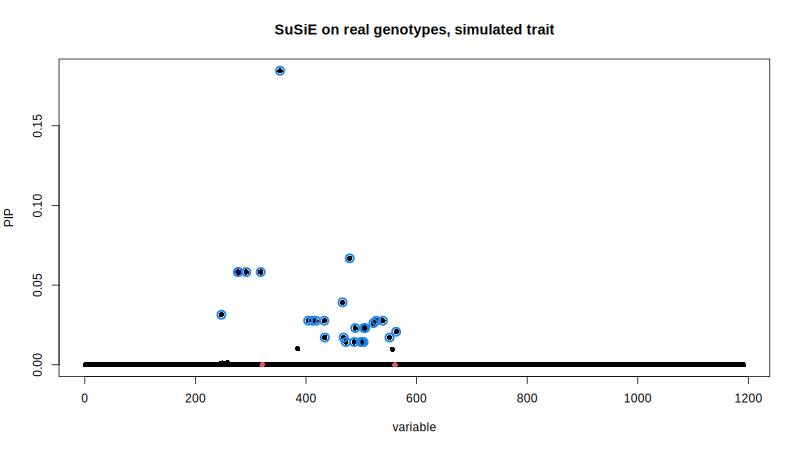

In [34]:
%%R -w 800 -h 450
susie_plot(fit, y = "PIP", b = beta, main = "SuSiE on real genotypes, simulated trait")

In [36]:
%%R
maf <- colMeans(X) / 2
maf <- pmin(maf, 1 - maf)
cat("MAF of true causals:", round(maf[causal], 3), "\n")

ur <- univariate_regression(X, y)
z  <- ur$betahat / ur$sebetahat
cat("|z| of true causals:", round(abs(z[causal]), 2), "\n")
cat("Rank of true causals by |z| (1 = strongest):", rank(-abs(z))[causal], "\n")
cat("Largest |z| overall:", round(max(abs(z)), 2), "\n")

cs <- fit$sets$cs[[1]]
cat("Top SNP in the credible set:", cs[which.max(fit$pip[cs])], "\n")
cat("Highest correlation between each causal and any SNP in the set:",
    round(sapply(causal, function(j) max(abs(cor(X[, j], X[, cs])))), 2), "\n")
cat("Purity of the set (min abs corr):", round(fit$sets$purity$min.abs.corr, 2), "\n")

MAF of true causals: 0.064 0.496 
|z| of true causals: 2.53 9.18 
Rank of true causals by |z| (1 = strongest): 577 53 
Largest |z| overall: 10.38 
Top SNP in the credible set: 353 
Highest correlation between each causal and any SNP in the set: 0.22 0.85 
Purity of the set (min abs corr): 0.92 


In [38]:
%%R
cs <- fit$sets$cs[[1]]
r <- abs(cor(X[, 321], X[, cs]))
best <- cs[which.max(r)]
cat("Stand-in SNP index:", best, " position:", pos[best], "\n")
cat("Its |z|:", round(abs(z[best]), 2), " vs true causal's |z|:", round(abs(z[321]), 2), "\n")
cat("Its PIP:", round(fit$pip[best], 3), "\n")

Stand-in SNP index: 277  position: 30133044 
Its |z|: 10.24  vs true causal's |z|: 9.18 
Its PIP: 0.058 
